In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from pathlib import Path

In [2]:
data_path = Path.cwd().parent / "data/raw/bloomberg/"
out_path = Path.cwd().parent / "data/processed"

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "lines.linewidth": 1.6, "legend.frameon": False,
})

In [3]:
TENORS = {"30DAY": 30, "60DAY": 60, "3MTH": 91, "6MTH": 182, "12MTH": 365, "18MTH": 547, "24MTH": 730}


def load_tenor(tenor):
    d = pd.read_csv(data_path / f"ovdv_impvol/SPX_IMPVOL_{tenor}.csv", parse_dates=True, index_col=0)
    d.columns = d.columns.str.extract(r"IMPVOL_([\d.]+)%")[0].astype(float)
    d.columns.name = "moneyness"
    return d


surf = pd.concat({t: load_tenor(t) for t in TENORS}, axis=1, names=["tenor", "moneyness"])
surf.shape

(1952, 63)

In [4]:
assert surf.index.is_monotonic_increasing and not surf.index.duplicated().any()
assert surf.notna().all().all()
assert all((surf[t].columns == surf["30DAY"].columns).all() for t in TENORS)
print(f"{surf.index[0]:%Y-%m-%d} to {surf.index[-1]:%Y-%m-%d}, {len(surf)} days, {surf.shape[1]} points")

2019-01-02 to 2026-10-07, 1952 days, 63 points


In [5]:
def neighbour_dev(df):
    return df - (df.shift(1) + df.shift(-1)) / 2


# a real move shows up in adjacent tenors too; a bad print only in one
dev = neighbour_dev(surf)
names = list(TENORS)
mismatch = pd.concat({
    t: pd.concat([(dev[t] - dev[n]).abs() for n in names[max(i - 1, 0):i + 2] if n != t]).groupby(level=0).min()
    for i, t in enumerate(names)
}, axis=1, names=["tenor", "moneyness"])

worst = mismatch.T.groupby(level="tenor", sort=False).max().T
pd.DataFrame({t: worst[t].nlargest(3).round(1).reset_index().astype(str).agg(" ".join, axis=1) for t in TENORS})

,30DAY,60DAY,3MTH,6MTH,12MTH,18MTH,24MTH
0,2022-09-20 46.8,2020-03-13 3.9,2020-03-13 3.9,2020-03-13 4.9,2022-03-30 4.6,2022-11-25 4.4,2022-11-25 6.1
1,2022-09-19 23.6,2020-03-12 3.5,2020-03-12 3.5,2020-03-16 3.8,2022-03-23 4.3,2020-03-13 2.5,2022-09-30 4.2
2,2022-09-21 23.2,2020-03-16 2.9,2020-03-16 2.9,2020-03-12 3.7,2022-03-22 3.3,2022-11-28 2.3,2020-03-16 3.9


In [6]:
THRESHOLD = 15  # same as 01_eda_series; largest real case is about 7 points
bad = worst.stack()
bad = bad[bad > THRESHOLD]
bad

date        tenor
2022-09-19  30DAY    23.63680
2022-09-20  30DAY    46.83595
2022-09-21  30DAY    23.23145
dtype: float64

In [7]:
# a whole smile is dropped when it is a bad print; neighbours flagged only because of it are kept
BAD_PRINTS = [("2022-09-20", "30DAY")]
assert set(BAD_PRINTS) <= {(f"{d:%Y-%m-%d}", t) for d, t in bad.index}

surf_clean = surf.copy()
for date, tenor in BAD_PRINTS:
    surf_clean.loc[date, tenor] = np.nan
d_surf = surf_clean.diff()

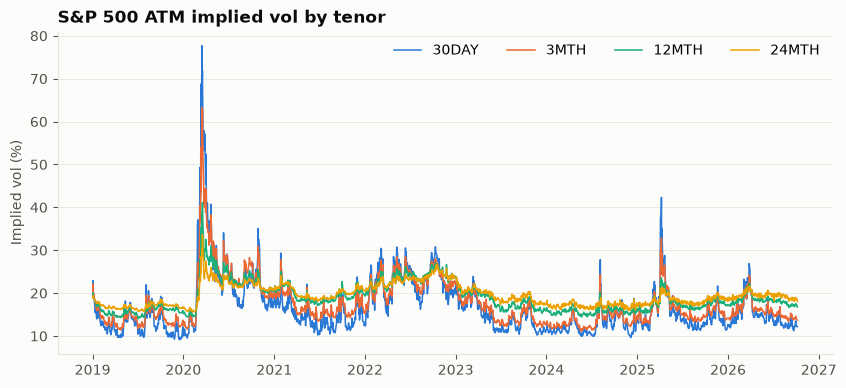

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for t, color in zip(["30DAY", "3MTH", "12MTH", "24MTH"], COLORS):
    ax.plot(surf_clean.index, surf_clean[(t, 100.0)], color=color, linewidth=1.1, label=t)
ax.set_title("S&P 500 ATM implied vol by tenor")
ax.set_ylabel("Implied vol (%)")
ax.legend(ncols=4)
plt.show()

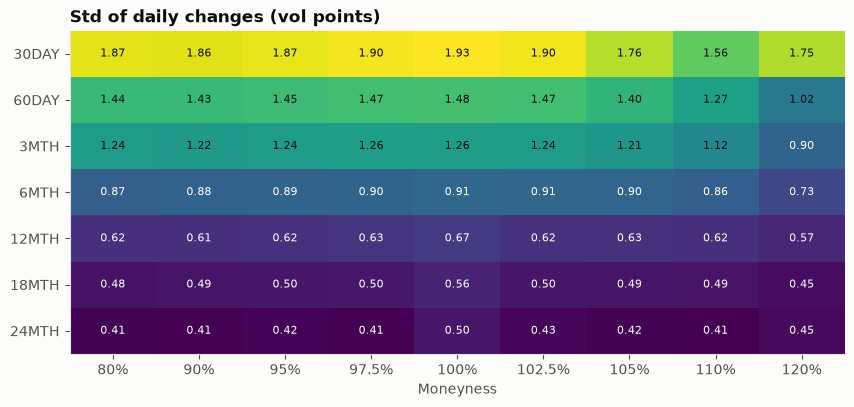

In [9]:
def plot_grid(ax, grid, title, cmap="viridis", center=False, fmt="{:.2f}"):
    vmax = np.nanmax(np.abs(grid.to_numpy())) if center else None
    im = ax.imshow(grid, cmap=cmap, aspect="auto", vmin=-vmax if center else None, vmax=vmax)
    is_moneyness = grid.columns.dtype == float
    ax.set_xticks(range(grid.shape[1]), [f"{m:g}%" for m in grid.columns] if is_moneyness else grid.columns)
    ax.set_yticks(range(grid.shape[0]), grid.index)
    ax.set_xlabel("Moneyness" if is_moneyness else "")
    ax.grid(False)
    ax.set_title(title)
    for (i, j), v in np.ndenumerate(grid.to_numpy()):
        ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                color="white" if (center and abs(v) > 0.6 * vmax) or (not center and v < np.nanmean(grid)) else INK)
    return im


fig, ax = plt.subplots(figsize=(10, 4.2))
plot_grid(ax, d_surf.std().unstack().loc[list(TENORS)], "Std of daily changes (vol points)")
plt.show()

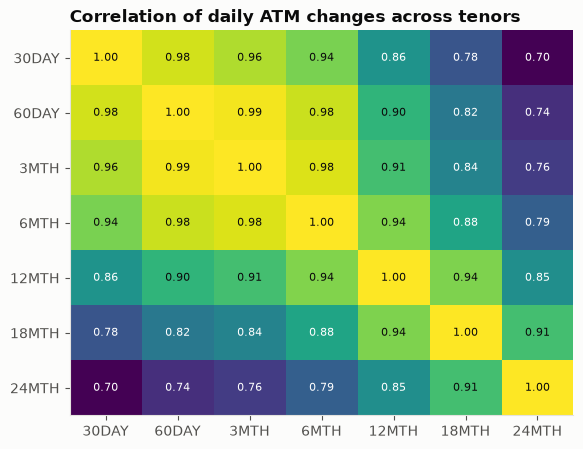

In [10]:
atm_changes = d_surf.xs(100.0, axis=1, level="moneyness")
fig, ax = plt.subplots(figsize=(6.5, 5))
plot_grid(ax, atm_changes.corr(), "Correlation of daily ATM changes across tenors")
plt.show()

In [11]:
pca = PCA().fit(d_surf.dropna())
pd.DataFrame({
    "explained": pca.explained_variance_ratio_[:5],
    "cumulative": pca.explained_variance_ratio_[:5].cumsum(),
}, index=[f"PC{i}" for i in range(1, 6)]).round(3)

,explained,cumulative
PC1,0.888,0.888
PC2,0.038,0.926
PC3,0.025,0.951
PC4,0.018,0.969
PC5,0.008,0.977


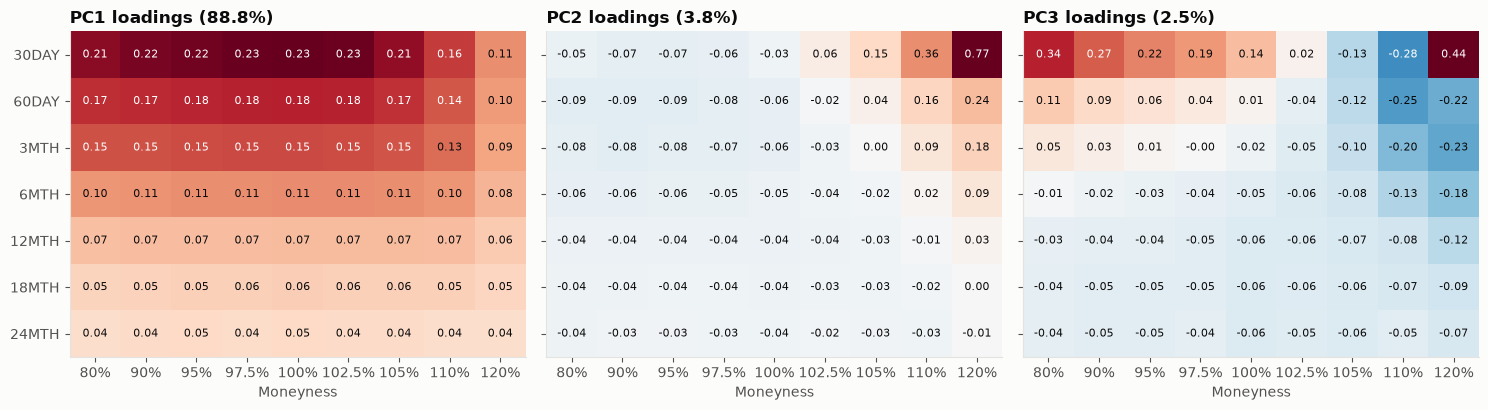

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for k, ax in enumerate(axes):
    grid = pd.Series(pca.components_[k], index=d_surf.columns).unstack().loc[list(TENORS)]
    plot_grid(ax, grid, f"PC{k + 1} loadings ({pca.explained_variance_ratio_[k]:.1%})", cmap="RdBu_r", center=True)
plt.tight_layout()
plt.show()

In [13]:
out_path.mkdir(exist_ok=True)
surf_clean.to_pickle(out_path / "surface_clean.pkl")